In [1]:
import pandas as pd

events = pd.DataFrame([
    ["O1001", "Order created", "2026-01-01"],
    ["O1001", "Order delivered", "2026-01-04"],
    ["O1001", "Invoice created", "2026-01-05"],
    ["O1001", "Payment received", "2026-01-08"],
    ["O1002", "Order created", "2026-01-02"],
    ["O1002", "Order delivered", "2026-01-06"],
    ["O1002", "Invoice created", "2026-01-07"],
    ["O1002", "Payment received", "2026-01-10"],
], columns=["Order ID", "Activity", "Timestamp"])

events["Timestamp"] = pd.to_datetime(events["Timestamp"])

events

,Order ID,Activity,Timestamp
0,O1001,Order created,2026-01-01
1,O1001,Order delivered,2026-01-04
2,O1001,Invoice created,2026-01-05
3,O1001,Payment received,2026-01-08
4,O1002,Order created,2026-01-02
5,O1002,Order delivered,2026-01-06
6,O1002,Invoice created,2026-01-07
7,O1002,Payment received,2026-01-10


In [3]:
total_orders = events["Order ID"].nunique()

print("Total number of orders:", total_orders)

total_activities = len(events)

print("Total number of activities:", total_activities)

Total number of orders: 2
Total number of activities: 8


In [4]:
#Delivery time calculation

created = events[events["Activity"] == "Order created"][
    ["Order ID", "Timestamp"]
].rename(columns={"Timestamp": "Order date"})

delivered = events[events["Activity"] == "Order delivered"][
    ["Order ID", "Timestamp"]
].rename(columns={"Timestamp": "Delivery date"})

delivery_times = created.merge(delivered, on="Order ID")

delivery_times["Delivery days"] = (
    delivery_times["Delivery date"] - delivery_times["Order date"]
).dt.days

print(delivery_times)
print("Average delivery time:",
      delivery_times["Delivery days"].mean(),
      "days")

  Order ID Order date Delivery date  Delivery days
0    O1001 2026-01-01    2026-01-04              3
1    O1002 2026-01-02    2026-01-06              4
Average delivery time: 3.5 days


In [5]:
#Paymenr time calculation

invoices = events[events["Activity"] == "Invoice created"][
    ["Order ID", "Timestamp"]
].rename(columns={"Timestamp": "Invoice date"})

payments = events[events["Activity"] == "Payment received"][
    ["Order ID", "Timestamp"]
].rename(columns={"Timestamp": "Payment date"})

payment_times = invoices.merge(payments, on="Order ID")

payment_times["Payment days"] = (
    payment_times["Payment date"] - payment_times["Invoice date"]
).dt.days

print(payment_times)
print("Average payment time:",
      payment_times["Payment days"].mean(),
      "days")

  Order ID Invoice date Payment date  Payment days
0    O1001   2026-01-05   2026-01-08             3
1    O1002   2026-01-07   2026-01-10             3
Average payment time: 3.0 days


In [6]:
#purchase to pay

purchases = pd.DataFrame([
    ["P1001", "Purchase request created", "2026-02-01"],
    ["P1001", "Purchase order sent", "2026-02-02"],
    ["P1001", "Goods received", "2026-02-07"],
    ["P1001", "Invoice received", "2026-02-08"],
    ["P1001", "Supplier paid", "2026-02-12"],
    ["P1002", "Purchase request created", "2026-02-03"],
    ["P1002", "Purchase order sent", "2026-02-04"],
    ["P1002", "Goods received", "2026-02-10"],
    ["P1002", "Invoice received", "2026-02-11"],
    ["P1002", "Supplier paid", "2026-02-15"],
], columns=["Purchase ID", "Activity", "Timestamp"])

purchases["Timestamp"] = pd.to_datetime(purchases["Timestamp"])

purchases

,Purchase ID,Activity,Timestamp
0,P1001,Purchase request created,2026-02-01
1,P1001,Purchase order sent,2026-02-02
2,P1001,Goods received,2026-02-07
3,P1001,Invoice received,2026-02-08
4,P1001,Supplier paid,2026-02-12
5,P1002,Purchase request created,2026-02-03
6,P1002,Purchase order sent,2026-02-04
7,P1002,Goods received,2026-02-10
8,P1002,Invoice received,2026-02-11
9,P1002,Supplier paid,2026-02-15


In [7]:
#supplier delivery time

purchase_orders = purchases[
    purchases["Activity"] == "Purchase order sent"
][["Purchase ID", "Timestamp"]].rename(
    columns={"Timestamp": "Purchase order date"}
)

goods_received = purchases[
    purchases["Activity"] == "Goods received"
][["Purchase ID", "Timestamp"]].rename(
    columns={"Timestamp": "Goods received date"}
)

supplier_delivery = purchase_orders.merge(
    goods_received,
    on="Purchase ID"
)

supplier_delivery["Supplier delivery days"] = (
    supplier_delivery["Goods received date"]
    - supplier_delivery["Purchase order date"]
).dt.days

print(supplier_delivery)

print(
    "Average supplier delivery time:",
    supplier_delivery["Supplier delivery days"].mean(),
    "days"
)

  Purchase ID Purchase order date Goods received date  Supplier delivery days
0       P1001          2026-02-02          2026-02-07                       5
1       P1002          2026-02-04          2026-02-10                       6
Average supplier delivery time: 5.5 days


In [8]:
# time taken to pay the supplier

invoice_received = purchases[
    purchases["Activity"] == "Invoice received"
][["Purchase ID", "Timestamp"]].rename(
    columns={"Timestamp": "Invoice date"}
)

supplier_paid = purchases[
    purchases["Activity"] == "Supplier paid"
][["Purchase ID", "Timestamp"]].rename(
    columns={"Timestamp": "Payment date"}
)

supplier_payment = invoice_received.merge(
    supplier_paid,
    on="Purchase ID"
)

supplier_payment["Payment days"] = (
    supplier_payment["Payment date"]
    - supplier_payment["Invoice date"]
).dt.days

print(supplier_payment)

print(
    "Average supplier payment time:",
    supplier_payment["Payment days"].mean(),
    "days"
)

  Purchase ID Invoice date Payment date  Payment days
0       P1001   2026-02-08   2026-02-12             4
1       P1002   2026-02-11   2026-02-15             4
Average supplier payment time: 4.0 days


In [9]:
#adding cancelled order details

cancelled_order = pd.DataFrame([
    ["O1003", "Order created", "2026-01-03"],
    ["O1003", "Order cancelled", "2026-01-04"],
], columns=["Order ID", "Activity", "Timestamp"])

cancelled_order["Timestamp"] = pd.to_datetime(
    cancelled_order["Timestamp"]
)

events_with_cancellation = pd.concat(
    [events, cancelled_order],
    ignore_index=True
)

events_with_cancellation

,Order ID,Activity,Timestamp
0,O1001,Order created,2026-01-01
1,O1001,Order delivered,2026-01-04
2,O1001,Invoice created,2026-01-05
3,O1001,Payment received,2026-01-08
4,O1002,Order created,2026-01-02
5,O1002,Order delivered,2026-01-06
6,O1002,Invoice created,2026-01-07
7,O1002,Payment received,2026-01-10
8,O1003,Order created,2026-01-03
9,O1003,Order cancelled,2026-01-04


In [11]:
#Cancellation rate

total_orders = events_with_cancellation["Order ID"].nunique()

cancelled_orders = events_with_cancellation[
    events_with_cancellation["Activity"] == "Order cancelled"
]["Order ID"].nunique()

cancellation_rate = (cancelled_orders / total_orders) * 100

print("Total orders:", total_orders)
print("Cancelled orders:", cancelled_orders)
print("Cancellation rate:", cancellation_rate, "%")

Total orders: 3
Cancelled orders: 1
Cancellation rate: 33.33333333333333 %


In [13]:
#forecasting demonstration

import pandas as pd
import matplotlib.pyplot as plt

weekly_kpis = pd.DataFrame({
    "Week": pd.date_range("2026-01-04", periods=8, freq="W"),
    "Order volume": [120, 135, 128, 145, 150, 142, 158, 165]
})

weekly_kpis



Forecasted order volume for next week: 155.0


In [14]:
forecast_value = weekly_kpis["Order volume"].tail(3).mean()

print("Forecasted order volume for next week:",
      round(forecast_value, 2))

Forecasted order volume for next week: 155.0


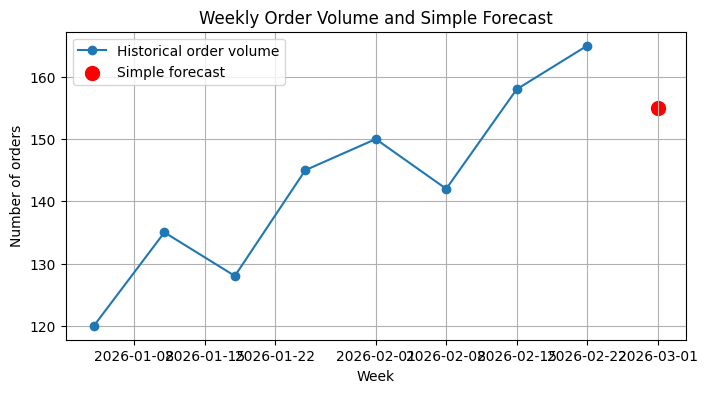

In [15]:
plt.figure(figsize=(8, 4))

plt.plot(
    weekly_kpis["Week"],
    weekly_kpis["Order volume"],
    marker="o",
    label="Historical order volume"
)

next_week = weekly_kpis["Week"].iloc[-1] + pd.Timedelta(weeks=1)

plt.scatter(
    next_week,
    forecast_value,
    color="red",
    s=100,
    label="Simple forecast"
)

plt.title("Weekly Order Volume and Simple Forecast")
plt.xlabel("Week")
plt.ylabel("Number of orders")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
#Model comparison for sample data

from sklearn.metrics import mean_absolute_error

train = weekly_kpis.iloc[:6]
test = weekly_kpis.iloc[6:]

actual_values = test["Order volume"].tolist()

# Model 1: Naive forecast
naive_predictions = [train["Order volume"].iloc[-1]] * len(test)
naive_mae = mean_absolute_error(actual_values, naive_predictions)

print("Naive Forecast")
print("Predictions:", naive_predictions)
print("Actual values:", actual_values)
print("MAE:", round(naive_mae, 2))
print()

# Model 2: Moving-average forecast
moving_average_value = train["Order volume"].tail(3).mean()
moving_average_predictions = [moving_average_value] * len(test)
moving_average_mae = mean_absolute_error(
    actual_values,
    moving_average_predictions
)

print("Moving-Average Forecast")
print("Predictions:", [round(value, 2) for value in moving_average_predictions])
print("Actual values:", actual_values)
print("MAE:", round(moving_average_mae, 2))

Naive Forecast
Predictions: [np.int64(142), np.int64(142)]
Actual values: [158, 165]
MAE: 19.5

Moving-Average Forecast
Predictions: [np.float64(145.67), np.float64(145.67)]
Actual values: [158, 165]
MAE: 15.83
